# Barrier and Interior Point Methods

This is the comprehensive companion to Lecture 24: local path proofs, primal/dual curvature, exact and modified Newton systems, stopping/positivity safeguards, barrier-specific globalization and the splitter modeling example. The implementation laboratory preserves both successful solves and a useful failure trace.

**Reading:** Biegler (2010), §6.3, pp.151–160, including the errata; Nocedal & Wright (2006), §19.1–§19.2, pp.564–568; Wachter & Biegler (2006), *On the implementation of an interior-point filter line-search algorithm for large-scale nonlinear programming*, §§2–3, pp.27–37, DOI [10.1007/s10107-004-0559-y](https://doi.org/10.1007/s10107-004-0559-y).

Start with the [local path proof](#barrier-local-proof), [Newton elimination](#barrier-newton), [stopping tests](#barrier-residuals) or [splitter model](#barrier-splitter). The named Interior-Point1/2 notebooks remain [equality Newton](Interior-Point1.ipynb) and [inertia correction](Interior-Point2.ipynb) references.

```{warning}
**AI-drafted prose, not yet reviewed by Prof. Dowling.**

Some of the writing on this page was drafted or edited by an AI assistant and has not yet been reviewed: 18 added markdown cells, measured against the last version of this notebook predating AI editing (2026-08-17).

This notice is about the *prose only*. It says nothing either way about the code, the numbers or the figures, which are checked separately. It is removed once the page has been reviewed.
```

(barrier-problem)=

## The bound-form problem and barrier domain

![Positive bound coordinates can still violate an equality.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-bound-interior.png)

Positive bound coordinates can still violate an equality.

Use the course Lagrangian $L=f+\mathbf v^{\mathsf T}\mathbf h-\mathbf u^{\mathsf T}\mathbf x$ for the simplified problem
$$\min_{\mathbf x}f(\mathbf x),\qquad\mathbf h(\mathbf x)=\mathbf0,\quad\mathbf x\ge\mathbf0.$$
Here $\mathbf J$ has constraint rows, $\mathbf u\ge\mathbf0$ is the lower-bound multiplier, and $\mathbf v$ is unrestricted. Nocedal–Wright's same-function equality multiplier reverses sign; its nonnegative bound multiplier retains its value. [Constrained Optimality](KKT-Multipliers.ipynb) owns the original KKT/slack derivations; [SQP](SQP.ipynb) gives the complete function/sign translation.

General inequalities become bound form by introducing slacks and an **augmented** equality vector. For example, $\mathbf g(\mathbf y)\le0$ becomes $\mathbf g(\mathbf y)+\mathbf s=0$, $\mathbf s\ge0$, with new variables $(\mathbf y,\mathbf s)$. One cannot simply delete arbitrary curved inequalities and retain the same original equalities with box bounds. This is equivalence by projection onto the original variables.

For fixed $\mu>0$, the simplified barrier problem minimizes
$$\phi_\mu(\mathbf x)=f(\mathbf x)-\mu\sum_i\log x_i,\qquad\mathbf h(\mathbf x)=0,\quad\mathbf x>0.$$
The logarithm requires positive bounded coordinates at every evaluation. Free variables need no barrier term; finite lower and upper bounds instead use $-\mu\log(x_i-l_i)$ and $-\mu\log(r_i-x_i)$. A fixed variable has no open interval and needs separate treatment. A box with an interior need not have an equality-feasible interior: $h(x)=x$ on $0\le x\le1$ admits only the boundary point. “Strict interior” in a central-path theorem means compatibility with the equalities, rather than an ambient open ball for an equality manifold.

Infeasible-start primal-dual methods maintain positive bound/slack variables while nonlinear equalities may be violated. When slacks are independent, positive slacks do not alone imply feasibility of the original nonlinear inequalities either. Nocedal–Wright pp. 564–566 distinguishes these interpretations.

A reformulation can preserve the NLP and change the barrier optimization. Splitting a free variable as $y=y_+-y_-$ with both parts nonnegative preserves its projected values, but the common shift $y_+=y_-=t$ leaves $y=0$ while $-\mu(\log y_++\log y_-)\to-\infty$. Such redundant barrier directions can destroy existence of a barrier minimum. Retain free variables as free, or justify a suitable lifting rather than assuming all positive-part representations preserve a useful barrier path. Biegler §6.3, p. 151; his Example 6.8 explicitly omits the barrier on its free first variable.

(barrier-paths)=

## Exact paths and what a barrier solution certifies

![Exact scalar barrier minima approach the original bound.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/barrier-scalar-central-path.png)

Exact scalar barrier minima approach the original bound.

For $\min x$ on $x\ge0$, $\phi_\mu'=1-\mu/x$, so $x(\mu)=\mu$, $u(\mu)=1$ and $xu=\mu$. The barrier minimizer is positive and approaches the original boundary solution; it is not the original minimizer at a positive weight. The scalar figure uses Biegler's four weights from Fig. 6.1, p. 152.

A nonempty active tangent makes curvature distinctions visible. Consider
$$f=x_1+\tfrac12(x_3-1)^2,\qquad h=x_1+x_2-1=0,\qquad\mathbf x\ge0.$$
Its original optimum is $(0,1,1)$ with $v^*=0$ and $\mathbf u^*=(1,0,0)$. The active bound and equality are independent, and the remaining tangent $(0,0,q_3)$ has curvature 1. Along the positive path, put
$$t(\mu)=\frac{2\mu}{1+2\mu+\sqrt{1+4\mu^2}},\qquad w(\mu)=\frac{1+\sqrt{1+4\mu}}2.$$
Then $\mathbf x=(t,1-t,w)$, $v=\mu/(1-t)$ and $\mathbf u=\mu/\mathbf x$ componentwise. These are stable closed-form roots, not a separate optimizer's approximation. Substitution into every perturbed KKT row verifies the path. Its primal error is $O(\mu)$; its original complementarity residual is exactly $\mu$ even when its barrier residual is zero. The laboratory computes both rather than inferring original convergence from a barrier solve.

(barrier-local-proof)=

## Local path theorem and proof

![Strict complementarity, active-tangent curvature and LICQ make the limiting Jacobian nonsingular.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-local-path-proof.png)

Strict complementarity, active-tangent curvature and LICQ make the limiting Jacobian nonsingular.

For twice continuously differentiable data, suppose a particular solution satisfies KKT, LICQ including active bounds, strict complementarity, and positive original Lagrangian curvature on the active tangent. There is a locally unique continuously differentiable primal-dual solution branch for sufficiently small positive $\mu$, converging to that KKT pair with $O(\mu)$ error. This is a local result about a selected branch; it does not guarantee that every start or arbitrary sequence of barrier minima reaches that solution. Biegler Thm. 6.7, pp. 152–153; Nocedal–Wright §19.1, p. 565.

Write
$$\mathbf F(\mathbf x,\mathbf v,\mathbf u;\mu)=\begin{bmatrix}\nabla f+\mathbf J^{\mathsf T}\mathbf v-\mathbf u\\\mathbf h\\\mathbf X\mathbf u-\mu\mathbf1\end{bmatrix},\qquad
\mathbf F'=\begin{bmatrix}\mathbf W&\mathbf J^{\mathsf T}&-\mathbf I\\\mathbf J&0&0\\\mathbf U&0&\mathbf X\end{bmatrix}.$$
Here $\mathbf W=\nabla^2f+\sum_j v_j\nabla^2h_j$ is the **original** Lagrangian Hessian. At the limiting solution, divide coordinates into active $\mathcal A$ and inactive $\mathcal I$. For a null vector $(\mathbf d_x,\mathbf d_v,\mathbf d_u)$ of this Jacobian, strict complementarity makes the last row imply $d_{x,i}=0$ on $\mathcal A$ and $d_{u,i}=0$ on $\mathcal I$. The middle row gives $\mathbf J\mathbf d_x=0$. Dot the first row with $\mathbf d_x$: the equality term vanishes, and each bound term vanishes because either its primal direction or its dual direction is zero. Thus $\mathbf d_x^{\mathsf T}\mathbf W\mathbf d_x=0$. Active-tangent SOSC forces $\mathbf d_x=0$. LICQ then makes $\mathbf J^{\mathsf T}\mathbf d_v-\mathbf d_u=0$ with inactive dual directions zero imply all remaining directions zero. The Jacobian is nonsingular.

The implicit-function theorem gives the local differentiable branch. Inactive primal coordinates and active multipliers remain positive by continuity. The positive product equation then forces positivity of the other coordinates/multipliers for $\mu>0$. Bounded branch derivatives yield the $O(\mu)$ primal-dual error. Nonsingularity is not a global basin-of-attraction theorem.

For completeness, the local branch also yields strict local barrier minima. Suppose, to the contrary, that unit equality-tangent directions along arbitrarily small weights have nonpositive barrier curvature. The active diagonal terms grow like $u_i^{*2}/\mu$, whereas $\mathbf W$ stays bounded. Their nonnegativity forces the active components of those directions to tend to zero. A subsequence has a unit limit in the original active tangent; continuity and SOSC give strictly positive limiting original curvature. The added barrier diagonal is nonnegative, a contradiction. This distinguishes equality-tangent positivity of the barrier subproblem from active-tangent positivity of the original problem.

Two counterexamples delimit the conclusion. For $f=(x-1)^2(x-3)^2$, $x\ge0$, both inactive-bound minima satisfy the local hypotheses and have nearby barrier branches; for small weights the branch near3 has the lower barrier value. Choosing a global barrier minimizer therefore need not approach the chosen local original minimizer1. With weak complementarity, $\min x^2$, $x\ge0$ has $x(\mu)=\sqrt{\mu/2}$ and $u(\mu)=\sqrt{2\mu}$: a path exists but its primal error is $O(\sqrt\mu)$, and the limiting complementarity Jacobian row is zero. Missing strict complementarity removes the stated regularity/rate guarantee, not every possible path.

(barrier-curvature)=

## Original, primal and primal-dual curvature

Keep three objects distinct:
$$\mathbf W=\nabla^2_{xx}L,\qquad
\mathbf H_{\rm bar}=\mathbf W+\mu\mathbf X^{-2},\qquad
\mathbf H_{\rm pd}=\mathbf W+\boldsymbol\Sigma,\quad\boldsymbol\Sigma=\mathbf X^{-1}\mathbf U.$$
The two added diagonal terms agree only when $\mathbf X\mathbf u=\mu\mathbf1$. A noncentral iterate can give different values, so adding a barrier diagonal to an already-barrier Hessian counts it twice. The bound term in the original Lagrangian is linear and adds no second derivatives. Biegler pp. 153–155.

Under strict complementarity, an active coordinate satisfies $x_i\sim\mu/u_i^*$, so $\mu/x_i^2\sim u_i^{*2}/\mu$. A unit direction in the **limiting active null space** has active components zero; the diverging terms contribute nothing there, while inactive diagonal contributions remain positive at finite $\mu$ and vanish as $O(\mu)$. An equality-only tangent generally permits active-coordinate motion and need not have this property. One must evaluate at positive path points: $\mu\mathbf X^{-2}$ is undefined at a literal zero coordinate.

Large entries alone do not imply a large condition number or singularity: a positive scalar matrix always has condition number1. Weak complementarity also changes the growth: the quadratic weak example has $\mu/x^2=2$, with total Hessian4. The laboratory compares actual full/primal-reduced curvature and full/condensed Jacobian condition numbers on the regular three-variable path. Its full primal-dual Jacobian stays nonsingular and well conditioned in the limit, while condensation introduces growing inverse-coordinate terms. This example illustrates Nocedal–Wright p. 567; it is not a universal numerical guarantee.

(barrier-newton)=

## Exact Newton elimination and regularization

![The product residual has a linear tangent, not an exactly preserved product after a finite step.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-complement-linearization.png)

The product residual has a linear tangent, not an exactly preserved product after a finite step.

![Exact elimination cancels the current bound dual and yields the smaller symmetric system.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-elimination-proof.png)

Exact elimination cancels the current bound dual and yields the smaller symmetric system.

At a positive iterate define $\mathbf r_d=\nabla f+\mathbf J^{\mathsf T}\mathbf v-\mathbf u$, $\mathbf r_h=\mathbf h$, and $\mathbf r_c=\mathbf X\mathbf u-\mu\mathbf1$. Newton solves the preceding Jacobian system with right side $-(\mathbf r_d,\mathbf r_h,\mathbf r_c)$. Eliminate only the last row:
$$\mathbf d_u=-\mathbf X^{-1}\mathbf r_c-\boldsymbol\Sigma\mathbf d_x.$$
Substitution gives
$$\begin{bmatrix}\mathbf W+\boldsymbol\Sigma&\mathbf J^{\mathsf T}\\\mathbf J&0\end{bmatrix}
\begin{bmatrix}\mathbf d_x\\\mathbf d_v\end{bmatrix}
=-\begin{bmatrix}\nabla f+\mathbf J^{\mathsf T}\mathbf v-\mu\mathbf X^{-1}\mathbf1\\\mathbf h\end{bmatrix}.$$
The cancellation $\mathbf r_d+\mathbf X^{-1}\mathbf r_c=\nabla f+\mathbf J^{\mathsf T}\mathbf v-\mu\mathbf X^{-1}\mathbf1$ works even away from centrality. Solve the symmetric system and back-substitute; do not form a dense matrix inverse. The multiplier unknown here is a **step**, not the updated QP multiplier from L21. Biegler (6.56)–(6.58), pp. 154–155.

For all-bound coordinates, the nonsymmetric system has dimension $2n+m$ and the condensed one $n+m$. With a subset of lower-bounded coordinates, a selection matrix places their duals in stationarity and their positive coordinate diagonals in complementarity. The laboratory supports that case so Example6.8's free first variable is treated correctly.

Inertia/rank safeguards may replace the condensed diagonal blocks by $\mathbf W+\boldsymbol\Sigma+\delta_W\mathbf I$ and $-\delta_A\mathbf I$. Then the defect in the **original** linearized stationarity row is $-\delta_W\mathbf d_x$, and $\mathbf h+\mathbf J\mathbf d_x=\delta_A\mathbf d_v$. The complementarity row remains satisfied by the recovery formula. A modified solve is not an exact Newton solve or automatic affine feasibility. [Equality Newton and Inertia](Interior-Point2.ipynb) owns the signature and congruence proofs. For the unregularized system, independent equality rows plus positive reduced curvature give signature $(n,m,0)$; a positive dual regularization can manufacture that signature even at an originally rank-deficient point.

Wachter–Biegler Algorithm IC, pp. 35–36, first tries the unmodified system, introduces a constraint perturbation if it detects zero eigenvalues, and increases the Hessian perturbation until the desired signature is obtained. It aborts to restoration when the search limit is reached. The heuristic does not establish uniform curvature merely by observing positive curvature each iteration. Nor does a numerically reported signature certify exact rank: the [Math Primer D4](../6/Math-Primer.ipynb) and L21 examples show why near-dependent rows and factorization tolerances matter. These general proofs are not repeated here.

The paper's printed Lagrangian (10), p. 29, omits the scalar bound product. Use $f+\mathbf v^{\mathsf T}\mathbf h-\mathbf u^{\mathsf T}\mathbf x$, consistent with its residual equations and the Hessian above.

(barrier-residuals)=

## Inner residual, original residual and multiplier scaling

![The inner shifted residual can pass its tolerance while the original product residual does not.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-residual-shift.png)

The inner shifted residual can pass its tolerance while the original product residual does not.

For the simplified unscaled problem,
$$E_\mu=\max\{\|\mathbf r_d\|_\infty,\|\mathbf r_h\|_\infty,\|\mathbf X\mathbf u-\mu\mathbf1\|_\infty\},\qquad
E_0=\max\{\|\mathbf r_d\|_\infty,\|\mathbf r_h\|_\infty,\|\mathbf X\mathbf u\|_\infty\}.$$
The triangle inequality gives $E_0\le E_\mu+\mu$ and, by reversing the shift, $|E_0-E_\mu|\le\mu$. At an exact central point, $E_\mu=0$ but $E_0=\mu$. An original KKT test also relies on the maintained primal/dual signs; residual magnitudes do not replace those signs. Biegler (6.52)–(6.54), pp. 153–154.

An inner rule $E_\mu\le\kappa_\epsilon\mu$ only bounds $E_0$ by $(\kappa_\epsilon+1)\mu$. With $\kappa_\epsilon=10$, $\mu=\epsilon_{\rm tol}/10$, $f=x$, $u=1$, $x=11\mu$, the inner residual is $10\mu$ and the original residual is $11\mu=1.1\epsilon_{\rm tol}$. Check $E_0$ separately. A literal nested loop that repeatedly skips its already-tolerated inner solve at the weight floor can stall; use an explicit progress or tighter-final-tolerance safeguard. This is an algebraic distinction, not a claim about production Ipopt failure.

The paper's unscaled stationarity/complementarity are additionally divided by factors
$$s_d=\frac{\max\{s_{\max},(\|\mathbf v\|_1+\|\mathbf u\|_1)/(m+n)\}}{s_{\max}},\qquad
s_c=\frac{\max\{s_{\max},\|\mathbf u\|_1/n\}}{s_{\max}}.$$
These factors are at least1 and adapt when average dual values are large. A small scaled residual can coexist with a larger unscaled one, so report which measure is used. The historical implementation uses $s_{\max}=100$; these are paper algorithm details rather than universal constants. Wachter–Biegler (5), pp. 27–28. The teaching laboratory prints unscaled residuals.

(barrier-algorithm)=

## Barrier updates and a complete teaching loop

Biegler Algorithm6.4 and the paper use
$$\mu_{l+1}=\max\{\epsilon_{\rm tol}/10,\min(\kappa_\mu\mu_l,\mu_l^{\theta_\mu})\},\qquad0<\kappa_\mu<1,\quad1<\theta_\mu<2.$$
The typical values $.2$ and $1.5$ switch to the power branch below $\mu=.04$. Decrease is superlinear **before the fixed positive floor**; an indefinitely floored sequence does not tend to zero. Barrier updates and inner Newton convergence have separate roles and assumptions.

A complete teaching implementation must specify:

1. Initialize positive bounded primal coordinates and bound duals, an equality multiplier, a barrier weight and finite retry limits. Equality feasibility is not required for an infeasible-start loop.
2. Check the original unscaled KKT residual $E_0$ and signs first. Return success only when the original criterion passes.
3. When the inner criterion passes, update the weight. Still take a genuine Newton/progress step if the original criterion has not passed, including at the floor. The laboratory does not repeatedly skip an already-tolerated inner solve. In the paper, after at least one Newton iteration, A-3.3 proceeds to direction computation after an update; initialization is a separate branch.
4. Build the actual residual/Jacobian, solve the condensed system, recover the bound-dual step and check the linear residual. If a modified curvature model is used, assess its actual slope rather than assuming exact Newton descent.
5. Compute primal/dual positivity caps. Apply the specified acceptance test. Backtracking exhaustion is a failure/stall status, not permission to accept the last trial.
6. Update the point and re-evaluate original residuals. Continue until success or a recorded iteration/solve failure.

The convex laboratory uses an unmodified exact Jacobian and one common capped step for primal and both dual blocks. For $\psi=\frac12\|\mathbf F\|_2^2$, its exact Newton direction has $D\psi=\mathbf F^{\mathsf T}\mathbf F'\mathbf d=-\|\mathbf F\|_2^2$. It backtracks on this residual merit. This is a teaching choice, not an implementation of Ipopt's filter, separate dual steps, scaling or restoration. Its positive diagonal addition and independent equality row make the toy's condensed system nonsingular. The actual run, starting at $(.2,.7,.5)$ with positive duals, reaches the original tolerance in seven accepted steps; outputs below are computed rather than copied into the notebook.

(barrier-globalization)=

## Fraction caps, centrality and barrier-specific globalization

![A positivity fraction is a domain safeguard, distinct from acceptance and equality feasibility.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ip-step-to-boundary.png)

A positivity fraction is a domain safeguard, distinct from acceptance and equality feasibility.

For positive $\mathbf z$ and $0<\tau<1$, the largest permissible step is
$$\alpha_{\max}=\min\left\{1,\min_{i:d_i<0}\frac{-\tau z_i}{d_i}\right\}.$$
When there are no negative direction entries, the cap is1. Every accepted $0<\alpha\le\alpha_{\max}$ keeps $\mathbf z+\alpha\mathbf d\ge(1-\tau)\mathbf z>0$. Apply it separately to primal bounded coordinates and bound duals if the specified algorithm uses separate steps. Biegler (6.60)–(6.62), p.155, shares the primal step with equality duals; Nocedal–Wright (19.8)–(19.9), p.567, specifies another dual-step convention. Do not mix the two formulas silently.

The usual $\tau_l=\max\{\tau_{\min},1-\mu_l\}$ is strictly below1 at a positive weight. Positivity is not nonlinear equality feasibility, sufficient decrease, numerical rank or a uniform distance from the boundary. The scalar-component activity uses a deliberately visible $\tau=.75$; the historical paper uses $.99$.

To keep $\boldsymbol\Sigma$ comparable to primal barrier curvature, the paper clamps each **new-point** bound dual into
$$\frac{\mu}{\kappa_\Sigma x_i^{k+1}}\le u_i^{k+1}\le\frac{\kappa_\Sigma\mu}{x_i^{k+1}},\qquad\kappa_\Sigma\ge1.$$
Consequently $\mu/(\kappa_\Sigma(x_i^{k+1})^2)\le\sigma_i^{k+1}\le\kappa_\Sigma\mu/(x_i^{k+1})^2$. Printed (17) uses the old point despite (16)'s new-point reset; the consistent bound uses the new point. This is not exact centrality, nor a guarantee that a numerical factorization succeeds. Wachter–Biegler p.30.

For a fixed inner weight, the filter compares $(\|\mathbf h\|_1,\phi_\mu)$, with the history/sufficient-decrease and near-feasible switching rules explained at [Constrained Globalization](Constrained-Globalization.ipynb). Changing $\mu$ changes the barrier objective; the paper resets filter history on weight updates. Small permissible primal fractions can trigger restoration rather than an endless backtrack. Bound-aware second-order corrections are evaluated inside the positive domain; an unsuccessful correction is discarded before ordinary backtracking resumes. The generic Maratos derivation remains in L22.

The fixed-barrier convergence theory uses bounded derivatives/curvature, appropriate rank bounds, comparability of primal/dual diagonals, uniformly positive reduced curvature and restoration conditions. Positivity at each iteration is not itself the uniform interior bound those arguments need. Biegler Thms.6.9–6.10, pp.157–158, distinguish feasible cluster points from a subsequence with vanishing stationarity. The errata repairs the stationarity expression to $\nabla\phi_\mu+\mathbf J^{\mathsf T}\mathbf v$. Do not promote a liminf statement to every cluster point being stationary without further hypotheses.

(barrier-failure)=

## A preserved failure and a fixed-barrier restart

Biegler Example6.8, p.156, minimizes $x_1$ subject to
$$h_1=x_1^2-x_2-1=0,\quad h_2=x_1-x_3-.5=0,\quad x_2,x_3\ge0.$$
The first coordinate is free, so its logarithm is omitted. The original solution is $(1,0,.5)$, with $\mathbf v^*=(-.5,0)$ and bounded-coordinate duals $(.5,0)$.

At $(-2,3,1)$, the full affine endpoint conditions give $-4d_1-d_2=0$ and $d_1-d_3=3.5$. Bounds on $x_2+d_2$ require $d_1\le.75$; bounds on $x_3+d_3$ require $d_1\ge2.5$. Thus the hard affine model is inconsistent even without a small trust radius. More generally, for $x_1<0$, eliminating the affine equalities imposes $d_1\le(1-x_1^2)/(2x_1)$ and $d_1\ge.5-x_1$, an incompatible pair. A short fraction can keep coordinates positive without reaching the full affine target.

The diagnostic below takes maximal primal and separate bound-dual fractions, with fixed $\mu=.1$ and **no merit/filter acceptance**. It shows collapsing caps and nonzero equality violation. Late ill-conditioned factorization warnings remain visible; the final values are numerical failure evidence, not an exact certificate. This diagnostic is not the complete safeguarded algorithm. A separate equality-feasible positive restart $(1.5,1.25,1)$ solves the same fixed-barrier equations in six residual-merit steps. Its inner residual is near roundoff, but its original complementarity residual remains $.1$. A successful fixed-barrier restart is not a general restoration implementation or original-NLP termination. Biegler pp.156–157.

(barrier-trust)=

## Scaled trust-region extensions

For fixed $\mu$, use $\tilde{\mathbf d}=\mathbf X^{-1}\mathbf d$ so absolute steps are smaller near a bound. The scaled gradient and curvature are
$$\tilde{\mathbf a}=\mathbf X\nabla f-\mu\mathbf1,\qquad
\tilde{\mathbf H}=\mathbf X\mathbf W\mathbf X+\mathbf X\boldsymbol\Sigma\mathbf X
=\mathbf X\mathbf W\mathbf X+\operatorname{diag}(\mathbf x\circ\mathbf u).$$
The equality linearization is $\mathbf J\mathbf X\tilde{\mathbf d}$. On exact centrality, the added scaled diagonal is $\mu\mathbf I$; approximate centrality gives the component range above, not necessarily identical eigenvalues of the whole scaled Hessian.

A normal model minimizes $\|\mathbf h+\mathbf J\mathbf X\tilde{\mathbf n}\|_2^2$ with $\|\tilde{\mathbf n}\|_2\le\xi_N\Delta$ and $\tilde{\mathbf n}\ge-(\tau/2)\mathbf1$. The combined tangential model minimizes $\tilde{\mathbf a}^{\mathsf T}\tilde{\mathbf d}+\frac12\tilde{\mathbf d}^{\mathsf T}\tilde{\mathbf H}\tilde{\mathbf d}$ with $\|\tilde{\mathbf d}\|_2\le\Delta$, $\mathbf J\mathbf X\tilde{\mathbf d}=\mathbf J\mathbf X\tilde{\mathbf n}$, and $\tilde{\mathbf d}\ge-\tau\mathbf1$. The normal point is a feasible candidate for the combined constraints, provided both radii are coordinated as specified. Approximate dogleg/truncated-CG solves need their usual decrease/curvature checks plus positivity safeguards.

Use the actual scaled model to compute predicted reduction; compare it with actual reduction at the same current weight. Shrink/recompute on rejection, update radius on accepted agreement and change the penalty weight only through the specified sufficient-violation-reduction rule. [L22's composite reference](Constrained-Globalization.ipynb) owns these generic mechanics; the scaled gradients, Hessians, equality rows and boundary inequalities are the new ingredients. A scaled radius alone is not acceptance or a universal cure for rank/conditioning problems.

Biegler (6.66)–(6.68), pp.159–160, states fixed-barrier convergence under its TR assumptions. The held errata adds coordinate upper/lower bounds to Thm.6.11 and its explanation, in addition to a lower bound on the barrier objective. Preserve those domain assumptions. The cited broader slack formulation also has infeasibility-stationary and dependent-active-gradient alternatives; the theorem must not be applied unchanged when those safeguards/regularity assumptions fail. These results address the fixed inner barrier problem, not a guaranteed global minimum of a nonconvex original NLP.

(barrier-splitter)=

## Splitter equations, limiting branches and active bounds

Take variables $(F,f_1,f_2,c_{\rm in},c_1,c_2)$ for nonnegative flows and mixture compositions. ModelA uses
$$F-f_1-f_2=0,\qquad Fc_{\rm in}-f_1c_1-f_2c_2=0,\qquad c_1-c_2=0.$$
The overall balance has two outlet minus signs. Its row Jacobian is
$$\mathbf J_A=\begin{bmatrix}1&-1&-1&0&0&0\\c_{\rm in}&-c_1&-c_2&F&-f_1&-f_2\\0&0&0&0&1&-1\end{bmatrix}.$$
At positive inlet flow, the balances imply $c_{\rm in}=c_1=c_2$. As flow tends to zero along this branch, row2 tends to $c_{\rm in}$ times row1, losing equality rank. The laboratory computes singular values along this branch.

At zero flow itself, the component balance says $0=0$. Only $c_1=c_2$ remains, and the inlet composition can differ: $(0,0,0,.3,.8,.8)$ is feasible for A. At equal composition the equality rank is2; at an unequal inlet value it can be3. Thus “zero flow always has this particular equality rank loss” is too broad.

ModelB uses $F-f_1-f_2=0$, $c_{\rm in}-c_1=0$, $c_{\rm in}-c_2=0$. Its equality Jacobian is constant with rank3. It agrees with A at positive inlet flow and adopts its continuous equal-composition limiting convention at zero flow. It removes A's extra zero-flow composition points, so this is a physical modeling choice rather than algebraic equivalence on the entire feasible set. Within bounded compositions and nonnegative flows, B is the closure of A's positive-inlet-flow branch.

Full NLP LICQ counts active bounds too. At zero flow, the three nonnegative flow bounds add rows $-\mathbf e_1^{\mathsf T},-\mathbf e_2^{\mathsf T},-\mathbf e_3^{\mathsf T}$. ModelB's overall balance is their linear combination, so its six active rows have rank5. Full LICQ still fails despite equality rank3. Yet MFCQ holds: direction $(2,1,1,0,0,0)$ lies in the equality null space and strictly increases all three flows. The [Constraint Qualifications reference](Constraint-Qualifications.ipynb) owns the general LICQ/MFCQ proof. This application distinguishes equality representation, physical conventions and bound regularity; neither a positive regularization nor an inertia count supplies missing physical information.

(barrier-software)=

## Software options and related architectures

[Official Ipopt options](https://coin-or.github.io/Ipopt/OPTIONS.html#OPT_fixed_variable_treatment) specify fixed-variable treatment. The documented default substitutes fixed variables as parameters; other choices add fixing equalities or relax fixing bounds. Bounds can also be relaxed during a solve. If a final point is projected back into the original bounds, the documented reported residuals refer to the unprojected point. Re-evaluate constraints at a projected point when that distinction affects interpretation. These are option-specific facts, not a claim that all solvers use one fixed-variable strategy.

The book's §6.4 contrasts simultaneous KKT solves with a particular nested active-set strategy that keeps process-model equations close to feasible by solving inner model equations. The outer derivatives then use the implicit solution map, assuming its Jacobian is nonsingular. The full reduced/implicit algebra already lives at [Equality Newton](Interior-Point1.ipynb) and [Math Primer](../6/Math-Primer.ipynb); do not duplicate it as a new barrier proof. Nested simulation is an architecture, not a guarantee of feasible iterates or a universal restriction to one outer optimizer. Compare derivative and inner-solve cost, sparsity, conditioning, residuals and failure behavior rather than assigning categorical winners to SQP or interior methods.

(barrier-laboratory)=

## Implementation laboratory

The code below computes the analytic path, the exact and modified Newton systems, the safeguarded convex teaching solve, the deliberately unglobalized failure, the fixed-barrier restart and splitter ranks. All lower-bound products use the selected bounded-coordinate indices, so free coordinates are handled correctly. Dense `scipy.linalg.solve` keeps the linear algebra visible. The implementation has no general-purpose filter, centrality clamp, sparse factorization or restoration phase; those complete mechanisms and their conditions are described above. Actual result archives and figure cells are shared with the handout.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
import scipy

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper
    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()

In [2]:
def fraction(z,d,tau=.99):
 """Return the positive-coordinate fraction cap for a proposed direction."""
 mask=d<0
 return float(min(1.,np.min(-tau*z[mask]/d[mask]))) if mask.any() else 1.
def quantities(x,v,u,mu,g,h,J,bounded):
 """Evaluate stationarity, equality and perturbed bound-product residuals."""
 ub=np.zeros(len(x));ub[bounded]=u
 rd=g(x)+J(x).T@v-ub;rh=h(x);rc=x[bounded]*u-mu
 return rd,rh,rc
def pdstep(x,v,u,mu,g,h,J,W,bounded,deltaW=0.,deltaA=0.):
 """Solve the condensed Newton system and recover the selected bound-dual step."""
 n=len(x);m=len(v);b=len(bounded);j=J(x);w=W(x,v);S=np.zeros((n,n));S[bounded,bounded]=u/x[bounded]
 rd,rh,rc=quantities(x,v,u,mu,g,h,J,bounded)
 rhs_top=rd.copy();rhs_top[bounded]+=rc/x[bounded]
 K=np.block([[w+S+deltaW*np.eye(n),j.T],[j,-deltaA*np.eye(m)]])
 solve=linalg.solve(K,-np.r_[rhs_top,rh],assume_a='sym')
 dx=solve[:n];dv=solve[n:];du=-rc/x[bounded]-(u/x[bounded])*dx[bounded]
 E=np.eye(n)[bounded,:]
 FJ=np.block([[w,j.T,-E.T],[j,np.zeros((m,m)),np.zeros((m,b))],[np.diag(u)@E,np.zeros((b,m)),np.diag(x[bounded])]])
 return dx,dv,du,K,FJ,np.r_[rd,rh,rc]


### Analytic path and actual curvature measurements

The following model has one strictly weighted active bound and a one-dimensional limiting active tangent. Closed-form path values are checked against the perturbed KKT equations before curvature or condition numbers are plotted.

In [3]:
def toy_f(x):
 """Evaluate the convex demonstration objective."""
 return float(x[0]+.5*(x[2]-1)**2)
def toy_g(x):
 """Evaluate its objective gradient."""
 return np.array([1.,0.,x[2]-1])
def toy_h(x):
 """Evaluate its equality residual."""
 return np.array([x[0]+x[1]-1])
def toy_J(x):
 """Return its row-oriented equality Jacobian."""
 return np.array([[1.,1.,0.]])
def toy_W(x,v):
 """Return its original Lagrangian Hessian."""
 return np.diag([0.,0.,1.])
def central(mu):
 """Return stable closed-form primal and dual central-path values."""
 t=2*mu/(1+2*mu+np.sqrt(1+4*mu*mu));s=(1+np.sqrt(1+4*mu))/2
 x=np.array([t,1-t,s]);v=np.array([mu/(1-t)]);u=mu/x
 return x,v,u


In [4]:
cp=[]
for mu in [.1,.05,.01,.001,1e-6,1e-9]:
 x,v,u=central(mu);rd,rh,rc=quantities(x,v,u,mu,toy_g,toy_h,toy_J,np.arange(3))
 assert max(np.max(abs(rd)),np.max(abs(rh)),np.max(abs(rc)))<1e-12
 dx,dv,du,K,FJ,F=pdstep(x,v,u,mu,toy_g,toy_h,toy_J,toy_W,np.arange(3))
 H=toy_W(x,v)+np.diag(mu/x**2);Z=np.array([[1/np.sqrt(2),0],[-1/np.sqrt(2),0],[0,1]])
 cp.append({'mu':mu,'x':x.tolist(),'v':v.tolist(),'u':u.tolist(),'E_mu':float(np.max(abs(F))),'E0':float(np.max(x*u)),
 'primal_error':float(linalg.norm(x-[0,1,1])),'full_barrier_hessian_condition':float(np.linalg.cond(H)),
 'equality_reduced_condition':float(np.linalg.cond(Z.T@H@Z)),'active_null_barrier_increment':float(mu/x[2]**2),
 'active_barrier_diagonal':float(mu/x[0]**2),
 'equality_direction_barrier_curvature':float(.5*mu*(x[0]**-2+x[1]**-2)),
 'full_PD_Jacobian_condition':float(np.linalg.cond(FJ)),'condensed_KKT_condition':float(np.linalg.cond(K)),
 'condensed_inertia':[int(np.sum(linalg.eigvalsh(K)>0)),int(np.sum(linalg.eigvalsh(K)<0)),int(np.sum(linalg.eigvalsh(K)==0))]})

path_data={"rows":cp}
helper.save_results("barrier-central-path",path_data,notebook="notebooks/7-dev/Barrier-Methods.ipynb",
    source_cells=[("notebooks/7-dev/Barrier-Methods.ipynb",t) for t in ["results:barrier-core","results:barrier-toy-model","results:barrier-central-path"]],
    description="Verified closed-form regular central path; full/reduced curvature and actual full/condensed condition numbers.",solver="closed-form roots and SciPy dense linear algebra "+scipy.__version__,quiet=True)
helper.save_results("barrier-curvature-geometry",path_data,notebook="notebooks/7-dev/Barrier-Methods.ipynb",
    source_cells=[("notebooks/7-dev/Barrier-Methods.ipynb",t) for t in ["results:barrier-core","results:barrier-toy-model","results:barrier-central-path"]],
    description="Same verified analytic path: active/equality direction versus limiting active-null curvature.",solver="closed-form roots and exact projected arithmetic",quiet=True)
results=path_data
print(f"{'mu':>10} {'x1':>12} {'x3':>12} {'E_mu':>12} {'E0':>12} {'cond(full PD)':>15} {'cond(condensed)':>16}")
for row in cp:
    print(f"{row['mu']:10g} {row['x'][0]:12.5g} {row['x'][2]:12.7g} {row['E_mu']:12.3e} {row['E0']:12.3e} {row['full_PD_Jacobian_condition']:15.5g} {row['condensed_KKT_condition']:16.5g}")


        mu           x1           x3         E_mu           E0   cond(full PD)  cond(condensed)
       0.1     0.090098     1.091608    9.714e-17    1.000e-01          4.2227           12.627
      0.05     0.047506     1.047723    4.163e-17    5.000e-02          4.1361           22.306
      0.01       0.0099     1.009902    2.220e-16    1.000e-02          4.0665           102.06
     0.001     0.000999     1.000999    5.421e-17    1.000e-03          4.0507             1002
     1e-06        1e-06     1.000001    4.888e-17    1.000e-06          4.0489            1e+06
     1e-09        1e-09            1    8.374e-17    1.000e-09          4.0489            1e+09


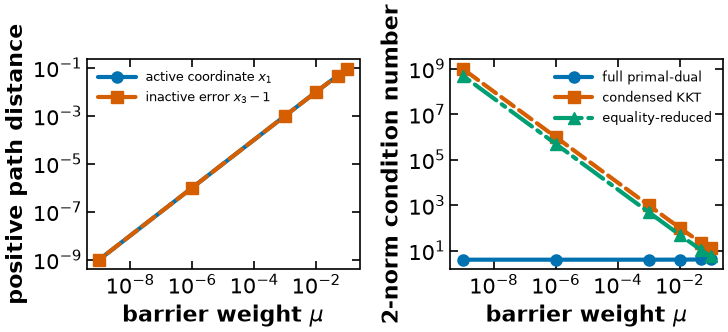

In [5]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.1))
mu=np.array([r["mu"] for r in results["rows"]])
x=np.array([r["x"] for r in results["rows"]])
axes[0].loglog(mu,x[:,0],"o-",color="#0072B2",label=r"active coordinate $x_1$")
axes[0].loglog(mu,x[:,2]-1,"s--",color="#D55E00",label=r"inactive error $x_3-1$")
axes[0].set(xlabel=r"barrier weight $\mu$",ylabel="positive path distance")
axes[0].legend(fontsize=9)
for key,label,ls,marker,col in [("full_PD_Jacobian_condition","full primal-dual","-","o","#0072B2"),("condensed_KKT_condition","condensed KKT","--","s","#D55E00"),("equality_reduced_condition","equality-reduced","-.","^","#009E73")]:
    axes[1].loglog(mu,[r[key] for r in results["rows"]],linestyle=ls,marker=marker,color=col,label=label)
axes[1].set(xlabel=r"barrier weight $\mu$",ylabel="2-norm condition number")
axes[1].legend(fontsize=9)
fig.tight_layout()
helper.save_figure(fig,"barrier-central-path",quiet=True)


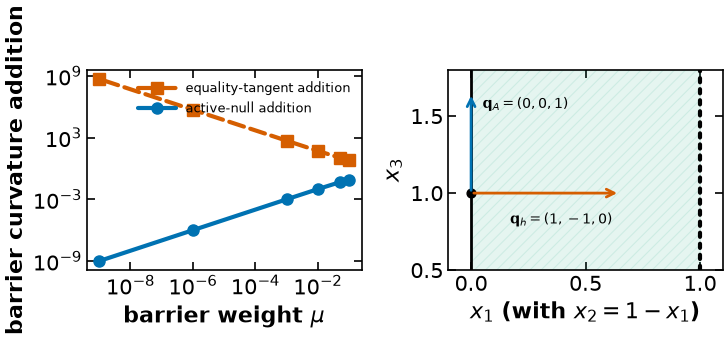

In [6]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.0))
mu=[r["mu"] for r in results["rows"]]
for key,label,col,ls,mark in [("equality_direction_barrier_curvature","equality-tangent addition","#D55E00","--","s"),("active_null_barrier_increment","active-null addition","#0072B2","-","o")]:
    axes[0].loglog(mu,[r[key] for r in results["rows"]],label=label,color=col,ls=ls,marker=mark)
axes[0].set(xlabel=r"barrier weight $\mu$",ylabel="barrier curvature addition")
axes[0].legend(fontsize=9)
axes[1].axvspan(0,1,color="#009E73",alpha=.1,hatch="///")
axes[1].axvline(0,color="black",lw=2);axes[1].axvline(1,color="black",ls=":")
axes[1].scatter(0,1,color="black",s=40)
axes[1].annotate("",(0,1.65),(0,1),arrowprops={"arrowstyle":"->","color":"#0072B2","lw":2})
axes[1].annotate("",(.65,1),(0,1),arrowprops={"arrowstyle":"->","color":"#D55E00","lw":2})
axes[1].text(.05,1.55,r"$\mathbf{q}_A=(0,0,1)$",fontsize=10)
axes[1].text(.17,.8,r"$\mathbf{q}_h=(1,-1,0)$",fontsize=10)
axes[1].set(xlabel=r"$x_1$ (with $x_2=1-x_1$)",ylabel=r"$x_3$",xlim=(-.1,1.1),ylim=(.5,1.8))
fig.tight_layout()
helper.save_figure(fig,"barrier-curvature-geometry",quiet=True)


### A complete teaching primal-dual loop

The loop checks the original unscaled residual first, uses the exact condensed direction, applies one common positivity cap and residual Armijo, and reports a finite-loop failure rather than accepting an exhausted backtrack. After a weight update it still computes a direction. This toy is convex with an independent equality row; its positive diagonal makes this unregularized solve well posed. This is not Ipopt's general filter/restoration implementation.

In [7]:
x=np.array([.2,.7,.5]);v=np.array([0.]);u=np.ones(3);mu=.1;tol=1e-8;hist=[];outer=0;status='iteration limit'
for iteration in range(180):
 rd,rh,rc=quantities(x,v,u,mu,toy_g,toy_h,toy_J,np.arange(3));E=float(max(np.max(abs(rd)),np.max(abs(rh)),np.max(abs(x*u))))
 Em=float(np.max(abs(np.r_[rd,rh,rc])))
 if E<=tol:status='converged';break
 if Em<=10*mu and iteration>0:
  mu=max(tol/10,min(.2*mu,mu**1.5));outer+=1
 # Always compute one direction after an update, even if old/current inner tolerance passes.
 dx,dv,du,K,FJ,F=pdstep(x,v,u,mu,toy_g,toy_h,toy_J,toy_W,np.arange(3))
 alpha=min(fraction(x,dx),fraction(u,du));slope=-float(F@F);psi=.5*float(F@F)
 for backtrack in range(60):
  xn=x+alpha*dx;vn=v+alpha*dv;un=u+alpha*du
  fn=np.r_[quantities(xn,vn,un,mu,toy_g,toy_h,toy_J,np.arange(3))]
  if .5*float(fn@fn)<=psi+1e-4*alpha*slope:break
  alpha*=.5
 else:status='line search failure';break
 assert np.all(xn>0) and np.all(un>0)
 np.testing.assert_allclose(FJ@np.r_[dx,dv,du],-F,atol=1e-10)
 hist.append({'k':iteration,'outer_updates':outer,'mu':mu,'x':x.tolist(),'v':v.tolist(),'u':u.tolist(),'E_mu':float(np.max(abs(F))),'E_mu_before_update':Em,'E0':E,'alpha':alpha,'backtracks':backtrack,'condensed_linear_residual':float(linalg.norm(K@np.r_[dx,dv]+np.r_[toy_g(x)+toy_J(x).T@v-mu/x,toy_h(x)],np.inf))})
 x,v,u=xn,vn,un
assert status=='converged' and max(np.max(abs(toy_g(x)+toy_J(x).T@v-u)),np.max(abs(toy_h(x))),np.max(abs(x*u)))<=tol

run_data={"history":hist,"status":status,"iterations":len(hist),"x":x.tolist(),"v":v.tolist(),"u":u.tolist(),"E0":E,"tolerance":tol}
helper.save_results("barrier-newton-run",run_data,notebook="notebooks/7-dev/Barrier-Methods.ipynb",
    source_cells=[("notebooks/7-dev/Barrier-Methods.ipynb",t) for t in ["results:barrier-core","results:barrier-toy-model","results:barrier-newton-run"]],
    description="Actual condensed primal-dual Newton teaching solve with original residual checks, positive common cap and residual Armijo.",solver="SciPy dense Newton "+scipy.__version__,quiet=True)
results=run_data
print("status:",status,"accepted steps:",len(hist),"x:",x,"v:",v,"u:",u,"E0:",E)
print(f"{'k':3} {'mu':>11} {'E_mu':>12} {'E0':>12} {'alpha':>10}")
for row in hist:
    print(f"{row['k']:3} {row['mu']:11.3e} {row['E_mu']:12.3e} {row['E0']:12.3e} {row['alpha']:10.5f}")


status: converged accepted steps: 7 x: [1.00000030e-09 9.99999999e-01 1.00000000e+00] v: [9.99999696e-10] u: [1.00000000e+00 9.99999696e-10 1.00000031e-09] E0: 1.0000003132108713e-09
k            mu         E_mu           E0      alpha
  0   1.000e-01    1.500e+00    1.500e+00    0.78158
  1   2.000e-02    3.276e-01    3.276e-01    0.98955
  2   2.828e-03    2.182e-02    2.465e-02    1.00000
  3   1.504e-04    3.046e-03    3.196e-03    1.00000
  4   1.845e-06    1.577e-04    1.596e-04    1.00000
  5   2.506e-09    1.867e-06    1.870e-06    0.99133
  6   1.000e-09    1.770e-08    1.870e-08    1.00000


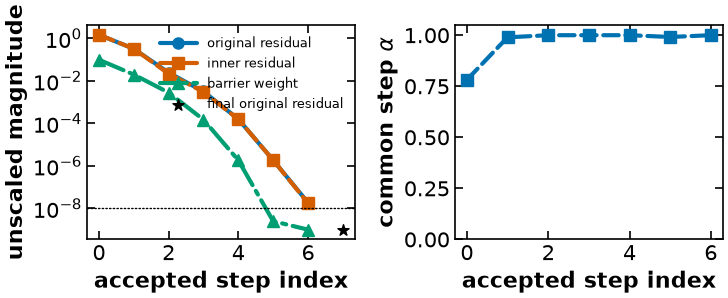

In [8]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.1))
rows=results["history"];k=[r["k"] for r in rows]
for key,label,col,ls,mark in [("E0","original residual","#0072B2","-","o"),("E_mu","inner residual","#D55E00","--","s"),("mu","barrier weight","#009E73","-.","^")]:
    axes[0].semilogy(k,[max(r[key],1e-16) for r in rows],label=label,color=col,linestyle=ls,marker=mark)
axes[0].scatter(len(rows),results["E0"],color="black",marker="*",s=70,label="final original residual")
axes[0].axhline(results["tolerance"],color="black",ls=":",lw=1)
axes[0].set(xlabel="accepted step index",ylabel="unscaled magnitude")
axes[0].legend(fontsize=9)
axes[1].plot(k,[r["alpha"] for r in rows],"s--",color="#0072B2")
axes[1].set(xlabel="accepted step index",ylabel=r"common step $\alpha$",ylim=(0,1.05))
fig.tight_layout()
helper.save_figure(fig,"barrier-newton-run",quiet=True)


In [9]:
# Compact actual run summary printed in the lecture handout.
print("Teaching primal-dual Newton: " + run_data["status"])
print("accepted steps =", run_data["iterations"])
print("x = (" + ", ".join(f"{z:.4e}" for z in run_data["x"]) + ")")
print("v = (" + ", ".join(f"{z:.4e}" for z in run_data["v"]) + ")")
print("u = (" + ", ".join(f"{z:.4e}" for z in run_data["u"]) + ")")
print(f"original E0 = {run_data['E0']:.4e}; tolerance = {run_data['tolerance']:.1e}")

Teaching primal-dual Newton: converged
accepted steps = 7
x = (1.0000e-09, 1.0000e+00, 1.0000e+00)
v = (1.0000e-09)
u = (1.0000e+00, 1.0000e-09, 1.0000e-09)
original E0 = 1.0000e-09; tolerance = 1.0e-08


### Bound-positive failure and a fixed-barrier restart

The first coordinate is free. The failure diagnostic uses maximal fractions with separate bound-dual steps and no acceptance merit. Its ill-conditioned-solve warnings are part of the observed failure. The separate positive restart uses the residual line search at fixed weight; it solves the inner equations and still has original complementarity error equal to that weight.

In [10]:
def fail_g(x):
 """Return the objective gradient for the bound-limited failure example."""
 return np.array([1.,0.,0.])
def fail_h(x):
 """Evaluate its two nonlinear equality residuals."""
 return np.array([x[0]**2-x[1]-1,x[0]-x[2]-.5])
def fail_J(x):
 """Return its row-oriented equality Jacobian."""
 return np.array([[2*x[0],-1,0],[1,0,-1.]])
def fail_W(x,v):
 """Return its original Lagrangian Hessian at the given multiplier."""
 return np.diag([2*v[0],0,0])


In [11]:
x=np.array([-2.,3.,1.]);v=np.zeros(2);u=.1/x[1:];b=np.array([1,2]);trace=[]
for k in range(8):
 dx,dv,du,K,FJ,F=pdstep(x,v,u,.1,fail_g,fail_h,fail_J,fail_W,b)
 alpha=fraction(x[b],dx[b]);alphau=fraction(u,du)
 trace.append({'k':k,'x':x.tolist(),'h':fail_h(x).tolist(),'violation':float(linalg.norm(fail_h(x),np.inf)),'alpha_max':alpha,'alpha_u':alphau,'dx':dx.tolist()})
 x=x+alpha*dx;v=v+alpha*dv;u=u+alphau*du
 assert np.all(x[b]>0) and np.all(u>0)
assert trace[-1]['alpha_max']<1e-6 and trace[-1]['violation']>1

failed_point=x.copy()
failed_violation=float(linalg.norm(fail_h(x),np.inf))
x=np.array([1.5,1.25,1.]);v=np.zeros(2);u=.1/x[1:];restored=[];status_r='limit'
for k in range(60):
 rd,rh,rc=quantities(x,v,u,.1,fail_g,fail_h,fail_J,b);F=np.r_[rd,rh,rc]
 if np.max(abs(F))<=1e-12:status_r='fixed barrier equations solved';break
 dx,dv,du,K,FJ,F=pdstep(x,v,u,.1,fail_g,fail_h,fail_J,fail_W,b)
 alpha=min(fraction(x[b],dx[b]),fraction(u,du));psi=.5*float(F@F)
 for backtrack in range(60):
  xn=x+alpha*dx;vn=v+alpha*dv;un=u+alpha*du
  Ft=np.r_[quantities(xn,vn,un,.1,fail_g,fail_h,fail_J,b)]
  if .5*float(Ft@Ft)<=psi-1e-4*alpha*float(F@F):break
  alpha*=.5
 else:status_r='line search failure';break
 restored.append({'k':k,'x':x.tolist(),'E_mu':float(np.max(abs(F))),'alpha':alpha})
 x,v,u=xn,vn,un
assert status_r=='fixed barrier equations solved' and np.all(x[b]>0) and np.all(u>0)

failure_data={"failed_history":trace,"failed_point":failed_point.tolist(),"failed_violation":failed_violation,
    "restored_history":restored,"restart_status":status_r,"restart_point":x.tolist(),"restart_v":v.tolist(),"restart_u":u.tolist(),
    "restart_E_mu":float(np.max(abs(F))),"restart_E0":float(max(np.max(abs(rd)),np.max(abs(rh)),np.max(x[b]*u))),"mu":.1}
helper.save_results("barrier-fraction-failure",failure_data,notebook="notebooks/7-dev/Barrier-Methods.ipynb",
    source_cells=[("notebooks/7-dev/Barrier-Methods.ipynb",t) for t in ["results:barrier-core","results:barrier-failure-model","results:barrier-fraction-failure"]],
    description="Actual fixed-mu maximal-fraction failure and separate positive restart; free first coordinate has no barrier.",solver="SciPy dense Newton; late ill-conditioning warnings retained",quiet=True)
results=failure_data
print(f"{'k':3} {'alpha_max':>13} {'equality violation':>20}")
for row in trace:print(f"{row['k']:3} {row['alpha_max']:13.5e} {row['violation']:20.7f}")
print("restart:",status_r,"steps:",len(restored),"x:",x,"E_mu:",failure_data["restart_E_mu"],"E0:",failure_data["restart_E0"])


k       alpha_max   equality violation
  0   1.66107e-01            3.5000000
  1   2.97760e-01            2.9186242
  2   1.88539e-02            2.0495758
  3   5.23983e-02            2.0109333
  4   8.89153e-04            1.9055637
  5   1.85724e-05            1.9038694
  6   1.94362e-07            1.9038340
  7   1.91429e-09            1.9038337
restart: fixed barrier equations solved steps: 6 x: [1.12606571 0.26802398 0.62606571] E_mu: 2.220446049250313e-16 E0: 0.10000000000000009


/var/folders/3w/vr4xmyqs451dg23xk88pqcg00000gq/T/ipykernel_36909/3141480757.py:16: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0408063766591447e-20.
  solve=linalg.solve(K,-np.r_[rhs_top,rh],assume_a='sym')
/var/folders/3w/vr4xmyqs451dg23xk88pqcg00000gq/T/ipykernel_36909/3141480757.py:16: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.051796188121626e-34.
  solve=linalg.solve(K,-np.r_[rhs_top,rh],assume_a='sym')
/var/folders/3w/vr4xmyqs451dg23xk88pqcg00000gq/T/ipykernel_36909/3141480757.py:16: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.539434377817376e-51.
  solve=linalg.solve(K,-np.r_[rhs_top,rh],assume_a='sym')


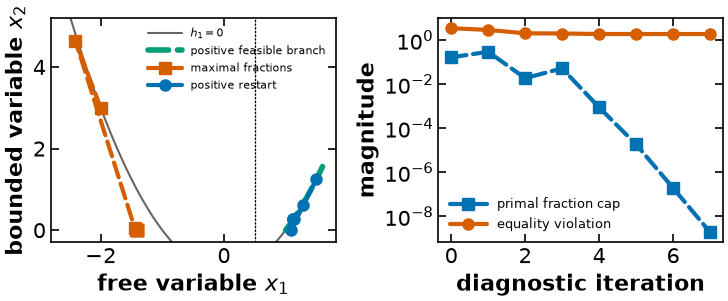

In [12]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.2))
grid=np.linspace(-2.6,1.6,300)
axes[0].plot(grid,grid**2-1,color="0.4",lw=1.5,label=r"$h_1=0$")
grid_feas=np.linspace(1,1.6,100)
axes[0].plot(grid_feas,grid_feas**2-1,color="#009E73",lw=4,label="positive feasible branch")
axes[0].axvline(.5,color="black",ls=":",lw=1)
for key,final,label,col,mark,ls in [("failed_history","failed_point","maximal fractions","#D55E00","s","--"),("restored_history","restart_point","positive restart","#0072B2","o","-")]:
    path=np.array([r["x"] for r in results[key]]+[results[final]])
    axes[0].plot(path[:,0],path[:,1],label=label,color=col,marker=mark,ls=ls)
axes[0].set(xlabel=r"free variable $x_1$",ylabel=r"bounded variable $x_2$",ylim=(-.3,5.2))
axes[0].legend(fontsize=8,loc="upper right")
for key,label,col,ls,mark in [("alpha_max","primal fraction cap","#0072B2","--","s"),("violation","equality violation","#D55E00","-","o")]:
    axes[1].semilogy([r["k"] for r in results["failed_history"]],[r[key] for r in results["failed_history"]],label=label,color=col,ls=ls,marker=mark)
axes[1].set(xlabel="diagnostic iteration",ylabel="magnitude")
axes[1].legend(fontsize=9,loc="lower left")
fig.tight_layout()
helper.save_figure(fig,"barrier-fraction-failure",quiet=True)


### Splitter equality rank and active-bound regularity

Compositions here are mass fractions in $[0,1]$. The extra zero-flow point is feasible for ModelA and excluded by ModelB. The matrix checks distinguish equality rank, the full active-row rank including nonnegative flows, and an MFCQ direction. Singular-value curves illustrate the limit; the symbolic row dependence above proves the limiting rank loss.

In [13]:
def modelA(z):
 """Evaluate the splitter mass balances and outlet composition equality."""
 F,a,b,c,d,e=z
 return np.array([F-a-b,F*c-a*d-b*e,d-e])
def jacA(z):
 """Return the splitter Model A row Jacobian."""
 F,a,b,c,d,e=z
 return np.array([[1,-1,-1,0,0,0],[c,-d,-e,F,-a,-b],[0,0,0,0,1,-1]],float)
JB=np.array([[1,-1,-1,0,0,0],[0,0,0,1,-1,0],[0,0,0,1,0,-1]],float)
zeq=np.array([0,0,0,.3,.3,.3]);zextra=np.array([0,0,0,.3,.8,.8]);assert np.all(modelA(zextra)==0)
assert np.linalg.matrix_rank(jacA(zeq))==2 and np.linalg.matrix_rank(jacA(zextra))==3 and np.linalg.matrix_rank(JB)==3
bound_rows=-np.eye(6)[:3];combined=np.vstack([JB,bound_rows]);strict_dir=np.array([2,1,1,0,0,0])
assert np.linalg.matrix_rank(combined)==5 and np.all(JB@strict_dir==0) and np.all(bound_rows@strict_dir<0)
sv=[]
for t in [1.,.1,.001,1e-6,0.]:
 z=np.array([t,.4*t,.6*t,.3,.3,.3]);sv.append({'flow':t,'singular_values':np.linalg.svd(jacA(z),compute_uv=False).tolist()})

splitter_data={"rows":sv,"JA_equal":jacA(zeq).tolist(),"JA_extra":jacA(zextra).tolist(),"JB":JB.tolist(),
    "extra_point":zextra.tolist(),"A_extra_residual":modelA(zextra).tolist(),"B_extra_residual":[float(zextra[3]-zextra[4]),float(zextra[3]-zextra[5])],
    "JA_equal_rank":int(np.linalg.matrix_rank(jacA(zeq))),"JA_extra_rank":int(np.linalg.matrix_rank(jacA(zextra))),
    "JB_rank":int(np.linalg.matrix_rank(JB)),"JB_sigma_min":float(np.linalg.svd(JB,compute_uv=False)[-1]),
    "active_rows":combined.tolist(),"active_rank":int(np.linalg.matrix_rank(combined)),"MFCQ_direction":strict_dir.tolist(),
    "equality_direction":(JB@strict_dir).tolist(),"active_bound_direction":(bound_rows@strict_dir).tolist()}
helper.save_results("barrier-splitter-rank",splitter_data,notebook="notebooks/7-dev/Barrier-Methods.ipynb",
    source_cells=[("notebooks/7-dev/Barrier-Methods.ipynb","results:barrier-splitter-rank")],
    description="Actual analytic splitter Jacobians, singular values, zero-flow extra point and full active-row LICQ/MFCQ checks.",solver="NumPy SVD/rank with exact symbolic row dependencies",quiet=True)
results=splitter_data
print("equality ranks A(equal), A(extra), B:",*[results[k] for k in ["JA_equal_rank","JA_extra_rank","JB_rank"]])
print("full active rank:",results["active_rank"],"of",len(results["active_rows"]),"rows")
print("extra point residuals A/B:",results["A_extra_residual"],results["B_extra_residual"])
print("MFCQ equality/bound directional derivatives:",results["equality_direction"],results["active_bound_direction"])


equality ranks A(equal), A(extra), B: 2 3 3
full active rank: 5 of 6 rows
extra point residuals A/B: [0.0, 0.0, 0.0] [-0.5, -0.5]
MFCQ equality/bound directional derivatives: [0.0, 0.0, 0.0] [-2.0, -1.0, -1.0]


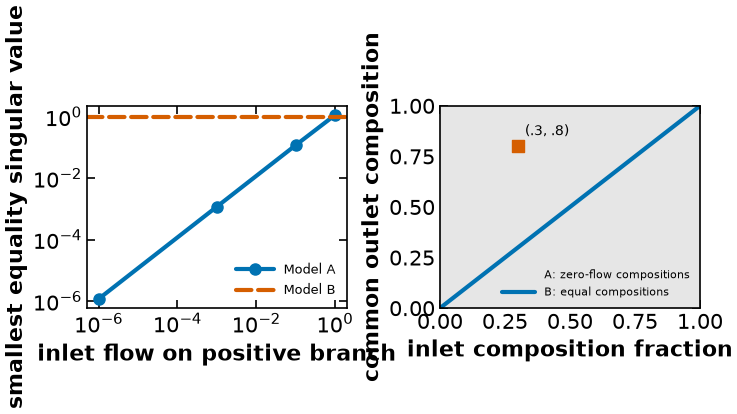

In [14]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(7.6,3.1))
rows=[r for r in results["rows"] if r["flow"]>0]
axes[0].loglog([r["flow"] for r in rows],[r["singular_values"][-1] for r in rows],"o-",color="#0072B2",label="Model A")
axes[0].axhline(results["JB_sigma_min"],color="#D55E00",ls="--",label="Model B")
axes[0].set(xlabel="inlet flow on positive branch",ylabel="smallest equality singular value")
axes[0].legend(fontsize=9)
axes[1].fill_between([0,1],[0,0],[1,1],color="0.9",hatch="///",label="A: zero-flow compositions")
axes[1].plot([0,1],[0,1],color="#0072B2",label="B: equal compositions")
axes[1].scatter(results["extra_point"][3],results["extra_point"][4],color="#D55E00",marker="s",s=65)
axes[1].annotate("(.3, .8)",(.3,.8),xytext=(5,8),textcoords="offset points",fontsize=10)
axes[1].set(xlabel="inlet composition fraction",ylabel="common outlet composition",xlim=(0,1),ylim=(0,1))
axes[1].legend(fontsize=8,loc="lower right")
fig.tight_layout()
helper.save_figure(fig,"barrier-splitter-rank",quiet=True)
